# Hectare Africa: Kenya maize farm risk score

**Model mission.** Make smallholder maize farmers in Kenya insurable by helping agricultural insurers judge each farm's risk at enrolment.

**The problem.** Most smallholder maize farmers in Kenya have no insurance. One bad season can wipe them out and lock them out of credit.

**Who uses this, and for what.** An insurance agent or underwriter, on the day a farmer signs up, before planting. They enter what they know about the field: where it is, its soil, and what the farmer plans to use. The model predicts the field's maize yield, and the insurer turns that into a low, medium or high risk band to decide cover and price.

**What I'm predicting.** `yield_kg_ha`, maize yield in kilograms per hectare.

**The data.** Aramburu Merlos, F., Tenorio, F. A., Mashingaidze, N., Sananka, A., Aston, S., & Grassini, P. (2024). *Maize management and yield of smallholder farmers in Sub-Saharan Africa between 2016 and 2022* (Version 2) [Dataset]. Zenodo. https://doi.org/10.5281/zenodo.11122388 (CC BY 4.0). One Acre Fund staff measured each field's yield at harvest, and the authors checked the yields for outliers.

In [1]:
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42
TARGET = "yield_kg_ha"

raw = pd.read_csv("One_Acre_Fund_MEL_maize_survey_data_2016-2022.csv")
print(f"{raw.shape[0]:,} rows, {raw.shape[1]} columns")
raw["country"].value_counts()

14,773 rows, 53 columns


country
kenya       7258
tanzania    3710
rwanda      2080
zambia       861
burundi      640
nigeria      115
uganda       109
Name: count, dtype: int64

## Why Kenya

I'm Kenyan, and it's the market I know best. Kenya also has the most fields in this survey, and they're all from the main long-rains season, so every row is the same kind of decision.

In [2]:
kenya = raw[raw["iso"] == "KEN"].reset_index(drop=True)
print(f"{kenya.shape[0]:,} rows, {kenya.shape[1]} columns")
print("Years:", sorted(kenya["year"].unique().tolist()))
print("Seasons:", list(kenya["season"].unique()))
kenya.head()

7,258 rows, 53 columns
Years: [2016, 2017, 2018, 2019, 2020]
Seasons: ['first season']


,year,country,iso,season,cz,lon,lat,strat,avg_season_gdd,avg_season_ai,avg_season_tavg,season_prec,season_prec_1,season_prec_2,season_prec_3,elev,twi,soil_rzpawhc,soil_clay,soil_pH,soil_orgC,soil_ECEC,plant_date,harvest_date,plant_date_dev,plant_doy,pl_m2,row_spacing,hybrid,hyb_type,hyb_mat,hyb_yor,hyb_tol_mln,hyb_tol_msv,hyb_tol_gls,hyb_tol_nclb,hyb_tol_rust,hyb_tol_ear_rot,N_kg_ha,P_kg_ha,K_kg_ha,compost,comp_kg_ha,manure,fert_in_hole,lime_kg_ha,weeding,pesticide,disease,pest,striga,water_excess,yield_kg_ha
0,2016,kenya,KEN,first season,7701,34.067,0.227,01_KEN7701S1,2509.099854,0.998492,21.275661,677.039708,228.759519,365.227443,83.052746,1280,8.322142,120.0,34.0,6.3,11.182494,13.879732,2016-04-13,NaN,22.0,104.0,NaN,70.666656,True,NaN,2.0,2004.0,False,False,False,False,False,False,51.892050,24.71050,0.0,False,0.0,NaN,True,0.0,NaN,NaN,False,False,NaN,False,1462.951369
1,2017,kenya,KEN,first season,7701,34.100,0.238,01_KEN7701S1,2552.900146,1.038017,21.507408,760.532583,154.624451,464.134379,141.773752,1288,10.117007,120.0,38.0,5.9,12.463738,12.463738,2017-03-31,2017-07-14,8.0,90.0,2.736283,68.666664,True,NaN,2.0,2004.0,False,False,False,False,False,False,51.892050,24.71050,0.0,False,0.0,NaN,True,0.0,False,True,False,True,NaN,False,2817.771269
2,2019,kenya,KEN,first season,7701,34.082,0.247,01_KEN7701S1,2580.099854,1.008526,21.651323,724.153837,181.676820,359.354439,183.122578,1243,7.909871,120.0,33.0,6.2,10.023176,10.023176,2019-04-15,2019-08-05,23.0,105.0,4.541739,72.666664,True,NaN,2.0,2004.0,False,False,False,False,False,False,27.873444,13.83788,0.0,False,0.0,NaN,True,0.0,False,False,False,True,NaN,False,0.000000
3,2020,kenya,KEN,first season,7701,34.098,0.232,01_KEN7701S1,2562.800049,1.018445,21.559790,998.342599,379.451999,428.776234,190.114366,1271,8.969049,120.0,32.0,6.0,10.023176,10.023176,2020-03-28,2020-07-16,6.0,88.0,3.986111,NaN,True,3_way_hyb,1.0,2003.0,False,False,True,False,False,True,44.478900,49.42100,0.0,True,NaN,True,False,0.0,True,False,False,True,True,False,4788.722787
4,2020,kenya,KEN,first season,7701,34.094,0.272,01_KEN7701S1,2612.800049,1.023641,21.824339,998.342599,379.451999,428.776234,190.114366,1226,6.008638,120.0,33.0,5.9,12.463738,11.182494,2020-02-05,2020-08-04,-46.0,36.0,2.277778,NaN,True,NaN,2.0,2004.0,False,False,False,False,False,False,51.892050,24.71050,0.0,False,NaN,NaN,False,0.0,False,NaN,False,False,True,False,2193.982268


In [3]:
features_all = kenya.drop(columns=TARGET)
numeric_columns = features_all.select_dtypes("number").columns
categorical_columns = features_all.columns.difference(numeric_columns)
print(f"{len(kenya):,} rows and {features_all.shape[1]} feature columns: "
      f"{len(numeric_columns)} numeric, {len(categorical_columns)} categorical (text or yes/no)")
print("Categorical columns:", list(categorical_columns))
kenya[TARGET].describe().round(1)

7,258 rows and 52 feature columns: 29 numeric, 23 categorical (text or yes/no)
Categorical columns: ['compost', 'country', 'disease', 'fert_in_hole', 'harvest_date', 'hyb_tol_ear_rot', 'hyb_tol_gls', 'hyb_tol_mln', 'hyb_tol_msv', 'hyb_tol_nclb', 'hyb_tol_rust', 'hyb_type', 'hybrid', 'iso', 'manure', 'pest', 'pesticide', 'plant_date', 'season', 'strat', 'striga', 'water_excess', 'weeding']


count    7258.0
mean     3019.7
std      1707.2
min         0.0
25%      1806.8
50%      2764.6
75%      3973.6
max      9903.5
Name: yield_kg_ha, dtype: float64

## Explore the data

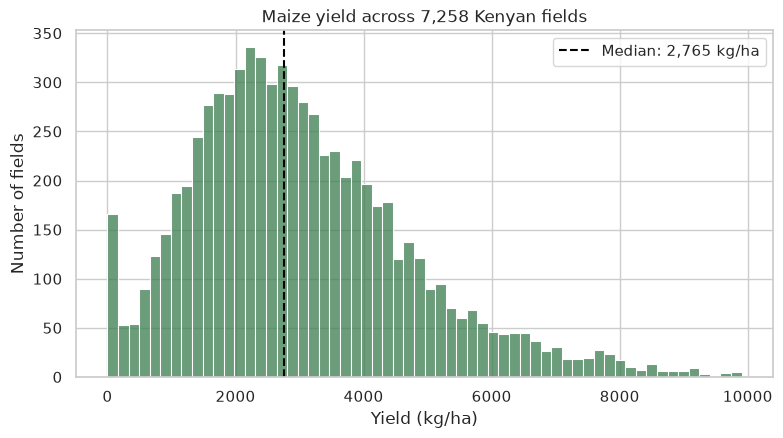

Fields with zero yield: 144
Fields under 1,000 kg/ha: 8.9%


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

median_yield = kenya[TARGET].median()
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(kenya[TARGET], bins=60, color="#3b7d4f", ax=ax)
ax.axvline(median_yield, color="black", linestyle="--", label=f"Median: {median_yield:,.0f} kg/ha")
ax.set(title=f"Maize yield across {len(kenya):,} Kenyan fields", xlabel="Yield (kg/ha)", ylabel="Number of fields")
ax.legend()
plt.show()

print(f"Fields with zero yield: {(kenya[TARGET] == 0).sum()}")
print(f"Fields under 1,000 kg/ha: {(kenya[TARGET] < 1000).mean():.1%}")

**What it shows.** Yield is skewed to the right: most fields harvest between 1,500 and 4,500 kg/ha (median 2,765), a long tail reaches almost 10,000 kg/ha, and 144 fields recorded zero. **What I decided.** I keep the zero-yield fields, because a crop failure is exactly the event an insurer has to price and the dataset's authors already screened the yields for statistical outliers. Because MSE squares errors, these extremes weigh heavily in the loss, so I also report RMSE in kg/ha to keep the errors readable.

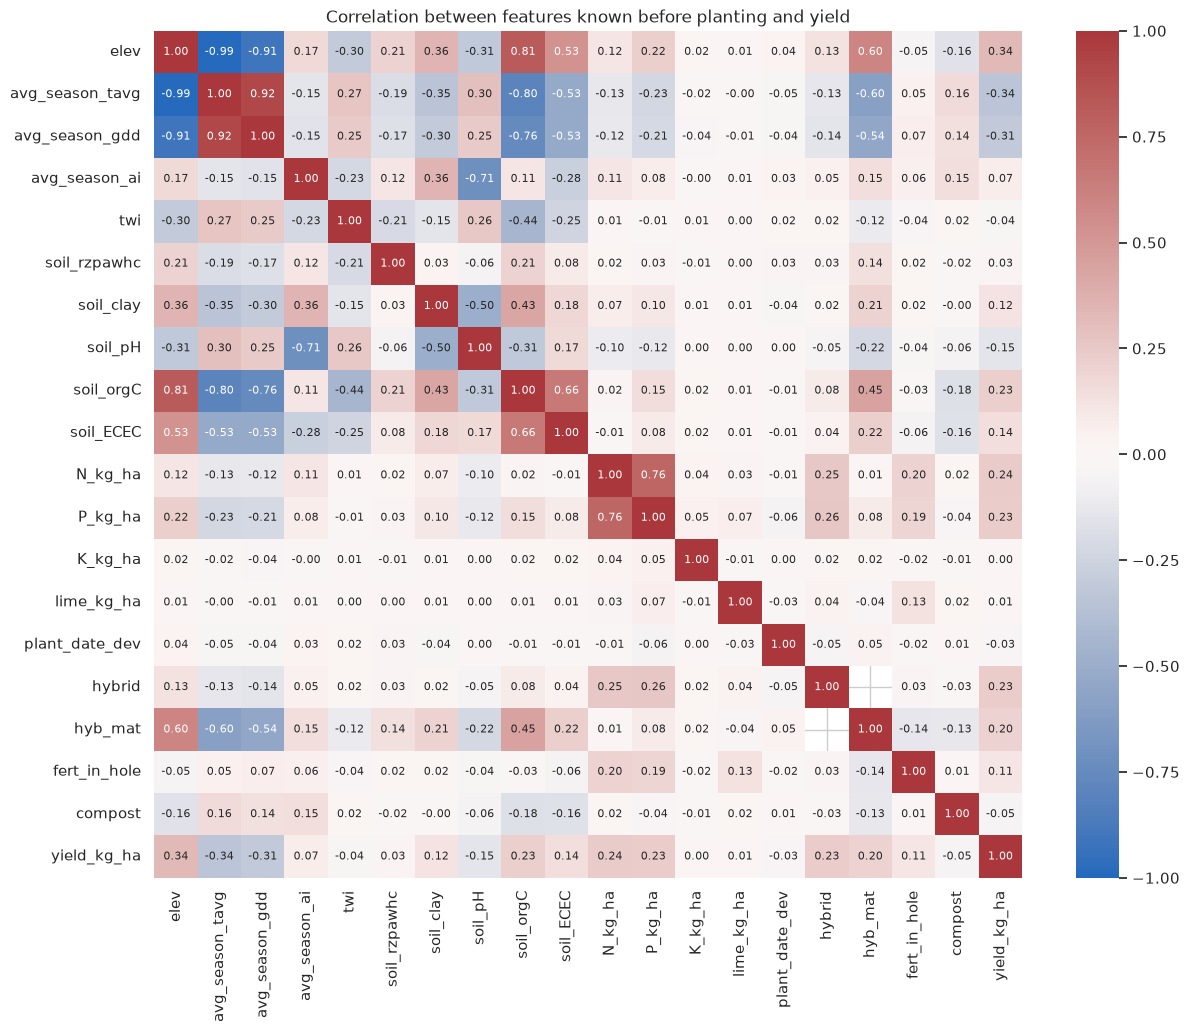

In [5]:
pre_planting = [
    "elev", "avg_season_tavg", "avg_season_gdd", "avg_season_ai", "twi", "soil_rzpawhc",
    "soil_clay", "soil_pH", "soil_orgC", "soil_ECEC", "N_kg_ha", "P_kg_ha", "K_kg_ha",
    "lime_kg_ha", "plant_date_dev", "hybrid", "hyb_mat", "fert_in_hole", "compost",
]
eda = kenya[pre_planting + [TARGET]].astype(float)

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(eda.corr(), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 8}, ax=ax)
ax.set_title("Correlation between features known before planting and yield")
plt.show()

**What it shows.** Elevation, average season temperature and growing degree days have a high collinearity (r = −0.99 and −0.91 with elevation), and yield's strongest links are only moderate: elevation +0.34, nitrogen +0.24, and phosphorus, hybrid seed and soil organic carbon +0.23 each. **What I decided.** I keep only elevation from that trio, because an agent can read it from a phone's GPS, and because no link is strong I also test non-linear models. Nitrogen and phosphorus also have a high collinearity (r = 0.76), so I test later whether both are needed (the blank hybrid and maturity cells appear because maturity is only recorded for hybrids).

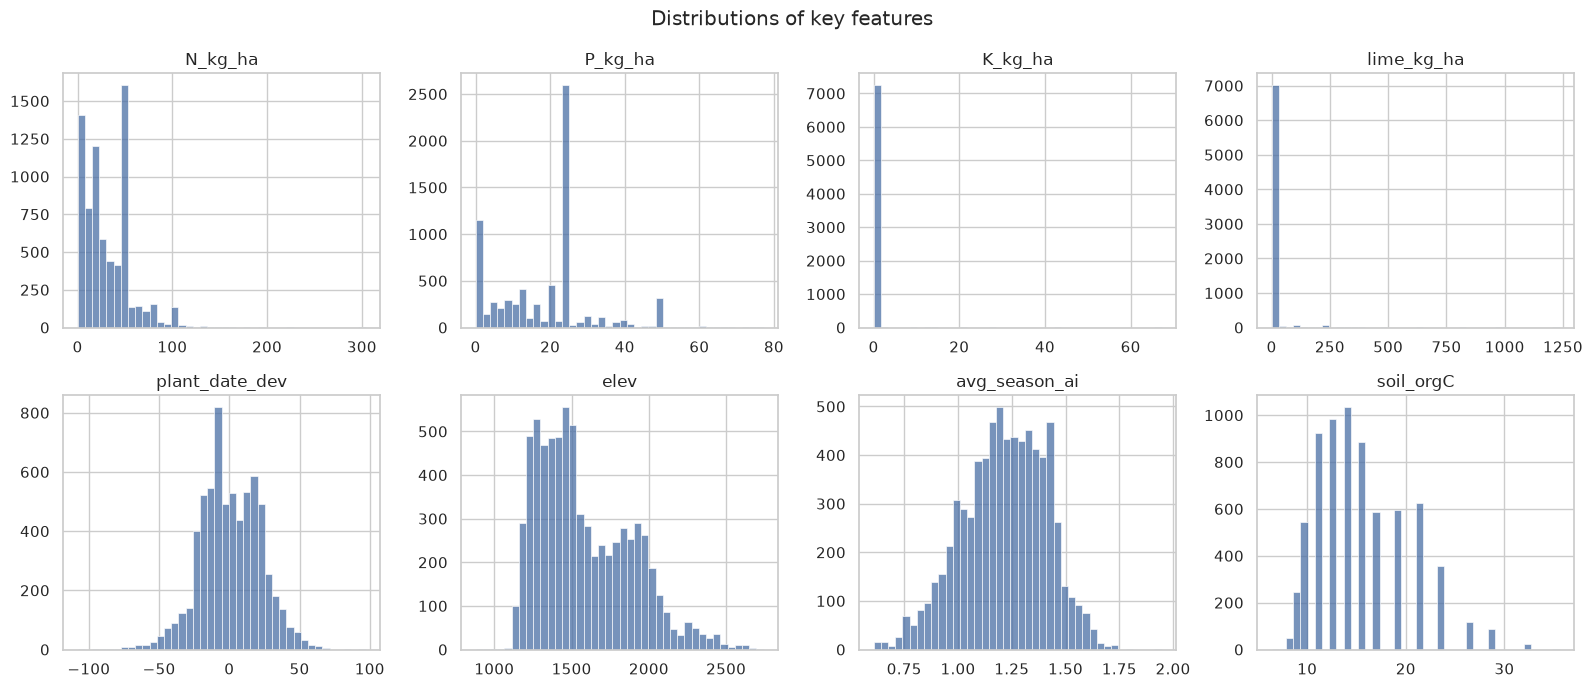

N_kg_ha: zero in 10.9% of fields
P_kg_ha: zero in 15.4% of fields
K_kg_ha: zero in 99.7% of fields
lime_kg_ha: zero in 96.1% of fields


In [6]:
to_plot = ["N_kg_ha", "P_kg_ha", "K_kg_ha", "lime_kg_ha", "plant_date_dev", "elev", "avg_season_ai", "soil_orgC"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, column in zip(axes.flat, to_plot):
    sns.histplot(kenya[column].dropna(), bins=40, color="#4a6fa5", ax=ax)
    ax.set(title=column, xlabel="", ylabel="")
fig.suptitle("Distributions of key features")
plt.tight_layout()
plt.show()

for column in ["N_kg_ha", "P_kg_ha", "K_kg_ha", "lime_kg_ha"]:
    print(f"{column}: zero in {(kenya[column] == 0).mean():.1%} of fields")

**What it shows.** Potassium is zero on 99.7% of fields and lime on 96.1%, while nitrogen and phosphorus pile up at zero and at about 50 and 25 kg/ha, which suggests many farmers apply the same standard rate. Planting dates centre on the local average, mostly within about three weeks of it, and elevation runs from about 900 to 2,700 m. **What I decided.** I drop potassium and lime because they carry almost no information (over 96% of fields don't use them), and I use these observed ranges to set the input limits in the API.

## Feature Engineering

I only keep what an insurer knows on the day a farmer signs up, before planting. So I dropped:

- **Things you only learn during the season:** rainfall, plant counts, row spacing, weeding, pesticide, pests, disease, striga, flooding and harvest date.
- **Labels and raw values:** country, season, survey codes, year, climate-zone code, GPS coordinates and calendar planting dates. `plant_date_dev` already says how early or late the farmer planted.
- **Mostly empty columns** (over 25% missing): manure, hybrid type, release year, the disease-tolerance flags and compost amount.
- **Almost always zero:** potassium and lime.
- **Temperature and growing degree days,** because they're basically elevation again, showing high collinearity (r = −0.99 and −0.91).
- **`hybrid` and `hyb_mat`,** which I combine into one `seed_type` column below.

In [7]:
DROPPED = {
    "only known once the season is under way": [
        "season_prec", "season_prec_1", "season_prec_2", "season_prec_3", "harvest_date", "pl_m2",
        "row_spacing", "weeding", "pesticide", "disease", "pest", "striga", "water_excess"],
    "identifiers, single values or raw forms": [
        "country", "iso", "season", "strat", "year", "cz", "lat", "lon", "plant_date", "plant_doy"],
    "mostly empty": [
        "manure", "hyb_type", "hyb_yor", "hyb_tol_mln", "hyb_tol_msv", "hyb_tol_gls",
        "hyb_tol_nclb", "hyb_tol_rust", "hyb_tol_ear_rot", "comp_kg_ha"],
    "almost always zero": ["K_kg_ha", "lime_kg_ha"],
    "high collinearity with elevation": ["avg_season_tavg", "avg_season_gdd"],
    "combined into seed_type": ["hybrid", "hyb_mat"],
}
KEPT = ["elev", "avg_season_ai", "twi", "soil_rzpawhc", "soil_clay", "soil_pH", "soil_orgC",
        "soil_ECEC", "N_kg_ha", "P_kg_ha", "plant_date_dev", "fert_in_hole", "compost"]

dropped_columns = [column for group in DROPPED.values() for column in group]
assert sorted(dropped_columns + KEPT + [TARGET]) == sorted(kenya.columns), "every column must be kept or dropped"

evidence = pd.DataFrame({
    "group": {column: group for group, columns in DROPPED.items() for column in columns},
    "missing %": kenya[dropped_columns].isna().mean().mul(100).round(1),
    "distinct values": kenya[dropped_columns].nunique(),
})
in_season_numeric = ["season_prec", "season_prec_1", "season_prec_2", "season_prec_3", "pl_m2"]
evidence["corr with yield"] = kenya[in_season_numeric].corrwith(kenya[TARGET]).round(2)
evidence

,group,missing %,distinct values,corr with yield
season_prec,only known once the season is under way,0.0,2331,0.18
season_prec_1,only known once the season is under way,0.0,2321,0.06
season_prec_2,only known once the season is under way,0.0,2281,0.05
season_prec_3,only known once the season is under way,0.0,2296,0.27
harvest_date,only known once the season is under way,20.8,648,NaN
pl_m2,only known once the season is under way,32.8,2978,0.30
row_spacing,only known once the season is under way,56.1,359,NaN
weeding,only known once the season is under way,15.7,2,NaN
pesticide,only known once the season is under way,51.3,2,NaN
disease,only known once the season is under way,0.0,2,NaN


The in-season columns do predict yield (season rainfall has r = 0.18), but nobody knows them when a farmer signs up, so using them would be cheating. That leaves 13 features, plus the seed type I build next.

### Building `seed_type`

`hybrid` says whether the farmer used hybrid seed, and `hyb_mat` says how fast it matures (1 = early, 2 = medium, 3 = late). Some fields have half-steps like 1.5 or 2.5, so I checked their yields to see where they fit.

In [8]:
hybrids = kenya[kenya["hybrid"] == True]
hybrids.groupby("hyb_mat", dropna=False)[TARGET].agg(["count", "median"]).round(0)

,count,median
hyb_mat,,
0.5,13,1555.0
1.0,1155,2735.0
1.5,134,2809.0
2.0,834,2652.0
2.5,849,2792.0
3.0,2442,3492.0
NaN,945,2228.0


Late hybrids (3) clearly stand out. The half-steps yield like early and medium hybrids, so I put each one in the class below it.

In [9]:
SEED_TYPES = ["local_or_opv", "hybrid_early", "hybrid_medium", "hybrid_late", "hybrid_unknown_maturity"]


def seed_type(is_hybrid, maturity):
    if not is_hybrid:
        return "local_or_opv"
    if pd.isna(maturity):
        return "hybrid_unknown_maturity"
    if maturity <= 1.5:
        return "hybrid_early"
    if maturity <= 2.5:
        return "hybrid_medium"
    return "hybrid_late"


data = kenya[KEPT + [TARGET]].copy()
data["seed_type"] = [seed_type(h, m) for h, m in zip(kenya["hybrid"], kenya["hyb_mat"])]
CANDIDATES = KEPT + ["seed_type"]

data.groupby("seed_type")[TARGET].agg(["count", "median"]).reindex(SEED_TYPES).round(0)

,count,median
seed_type,,
local_or_opv,886,1781.0
hybrid_early,1302,2736.0
hybrid_medium,1683,2703.0
hybrid_late,2442,3492.0
hybrid_unknown_maturity,945,2228.0


Late hybrids yield about double what local seed gives (median 3,492 vs 1,781 kg/ha). When maturity wasn't recorded, I kept that as its own group instead of guessing.

## Turning categories into numbers

- The yes/no columns (`fert_in_hole`, `compost`) become 1 and 0. Blank `compost` values get filled later.
- `seed_type` becomes four 0/1 columns (one-hot encoding). Local seed is the baseline, so it's the one without its own column.

In [10]:
for column in ["fert_in_hole", "compost"]:
    before = data[column].map(repr).value_counts(dropna=False).to_dict()
    data[column] = data[column].map({True: 1, False: 0})
    after = data[column].value_counts(dropna=False).to_dict()
    print(f"{column}\n  before: {before}\n  after:  {after}")

fert_in_hole
  before: {'False': 4592, 'True': 2666}
  after:  {0: 4592, 1: 2666}
compost
  before: {'False': 4684, 'True': 1361, 'nan': 1213}
  after:  {0.0: 4684, 1.0: 1361, nan: 1213}


In [11]:
from sklearn.preprocessing import OneHotEncoder

seed_encoder = OneHotEncoder(categories=[SEED_TYPES], drop="first", sparse_output=False)
seed_onehot = pd.DataFrame(seed_encoder.fit_transform(data[["seed_type"]]),
                           columns=seed_encoder.get_feature_names_out(), index=data.index).astype(int)
pd.concat([data["seed_type"], seed_onehot], axis=1).drop_duplicates().set_index("seed_type").reindex(SEED_TYPES)

,seed_type_hybrid_early,seed_type_hybrid_medium,seed_type_hybrid_late,seed_type_hybrid_unknown_maturity
seed_type,,,,
local_or_opv,0,0,0,0
hybrid_early,1,0,0,0
hybrid_medium,0,1,0,0
hybrid_late,0,0,1,0
hybrid_unknown_maturity,0,0,0,1


The five seed types are fixed in advance, so the encoder doesn't learn anything from the data. The same encoder is saved inside the model, so the app can send the seed type as plain text.

## Splitting, then scaling

I keep 20% of the fields aside as the test set. The scaler, and the medians used to fill blanks, only learn from the training set.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

X = data[CANDIDATES]
y = data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Train: {len(X_train):,} fields | Test: {len(X_test):,} fields")


def build_preprocessor(numeric_features):
    encode = ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"), numeric_features),
        ("seed_type", OneHotEncoder(categories=[SEED_TYPES], drop="first"), ["seed_type"]),
    ])
    return Pipeline([("encode", encode), ("scale", StandardScaler())])


numeric_candidates = [column for column in CANDIDATES if column != "seed_type"]
preprocessor = build_preprocessor(numeric_candidates).fit(X_train)
encoded_names = preprocessor.named_steps["encode"].get_feature_names_out()
train_scaled = pd.DataFrame(preprocessor.transform(X_train), columns=encoded_names)
test_scaled = pd.DataFrame(preprocessor.transform(X_test), columns=encoded_names)

pd.DataFrame({
    "train mean": train_scaled.mean(), "train std": train_scaled.std(ddof=0),
    "test mean": test_scaled.mean(), "test std": test_scaled.std(ddof=0),
}).round(3)

Train: 5,806 fields | Test: 1,452 fields


,train mean,train std,test mean,test std
numeric__elev,-0.0,1.0,0.014,1.001
numeric__avg_season_ai,0.0,1.0,0.012,0.993
numeric__twi,0.0,1.0,-0.019,0.970
numeric__soil_rzpawhc,0.0,1.0,0.048,0.966
numeric__soil_clay,0.0,1.0,0.027,0.997
numeric__soil_pH,0.0,1.0,-0.020,1.014
numeric__soil_orgC,0.0,1.0,0.008,0.992
numeric__soil_ECEC,-0.0,1.0,0.026,1.040
numeric__N_kg_ha,0.0,1.0,-0.005,0.984
numeric__P_kg_ha,-0.0,1.0,0.003,1.000


Training columns now have a mean of 0 and a standard deviation of 1. The test columns are close but not exact, which shows the scaler never saw them.

## Which features matter most

Correlation only catches straight-line links, so I ran two quick tests on the training set only:

1. **Permutation importance:** shuffle one feature and see how much worse the model gets.
2. **Drop one feature at a time:** if the error moves by less than 0.1%, the feature adds too little, so I drop it. That also keeps the app's form shorter.

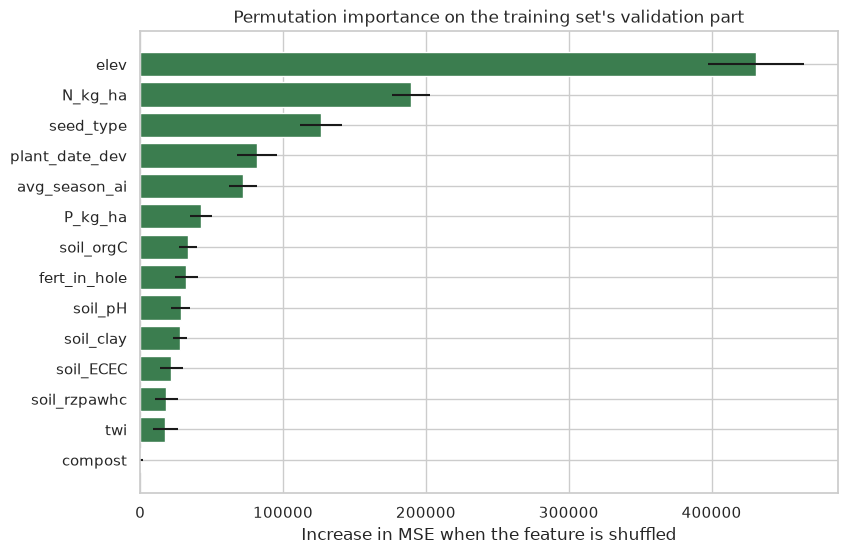

In [13]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=RANDOM_STATE)
probe = Pipeline([
    ("prep", build_preprocessor(numeric_candidates)),
    ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5,
                                    random_state=RANDOM_STATE, n_jobs=-1)),
]).fit(X_fit, y_fit)
permutation = permutation_importance(probe, X_val, y_val, scoring="neg_mean_squared_error",
                                     n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.DataFrame({"MSE increase": permutation.importances_mean,
                           "spread": permutation.importances_std}, index=CANDIDATES).sort_values("MSE increase")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(importance.index, importance["MSE increase"], xerr=importance["spread"], color="#3b7d4f")
ax.set(title="Permutation importance on the training set's validation part",
       xlabel="Increase in MSE when the feature is shuffled")
plt.show()

Elevation matters most by far, then nitrogen, seed type, planting date and aridity. Compost adds nothing. Phosphorus comes sixth, but it has a high collinearity with nitrogen (r = 0.76), so the next test checks whether we need it.

In [14]:
from sklearn.model_selection import RepeatedKFold, cross_val_score

repeated_cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)


def cv_mse(features):
    numeric = [column for column in features if column != "seed_type"]
    pipe = Pipeline([
        ("prep", build_preprocessor(numeric)),
        ("model", RandomForestRegressor(n_estimators=150, min_samples_leaf=5, max_features=0.5,
                                        random_state=RANDOM_STATE, n_jobs=-1)),
    ])
    scores = -cross_val_score(pipe, X_train[features], y_train, cv=repeated_cv, scoring="neg_mean_squared_error")
    return scores.mean(), scores.std() / np.sqrt(len(scores))


baseline_mse, baseline_se = cv_mse(CANDIDATES)
drop_one = pd.DataFrame(
    {column: cv_mse([c for c in CANDIDATES if c != column])[0] for column in numeric_candidates},
    index=["CV MSE without it"]).T
drop_one["change vs all candidates"] = drop_one["CV MSE without it"] - baseline_mse
drop_one["change %"] = drop_one["change vs all candidates"] / baseline_mse * 100
print(f"All {len(CANDIDATES)} candidates: CV MSE {baseline_mse:,.0f} (standard error {baseline_se:,.0f})")
drop_one.sort_values("change vs all candidates").style.format(
    {"CV MSE without it": "{:,.0f}", "change vs all candidates": "{:+,.0f}", "change %": "{:+.2f}%"})

All 14 candidates: CV MSE 2,176,187 (standard error 23,550)


,CV MSE without it,change vs all candidates,change %
twi,"2,175,608",-579,-0.03%
P_kg_ha,"2,177,438","+1,251",+0.06%
compost,"2,177,600","+1,413",+0.06%
soil_pH,"2,183,643","+7,456",+0.34%
soil_ECEC,"2,186,149","+9,962",+0.46%
soil_clay,"2,186,537","+10,350",+0.48%
soil_orgC,"2,187,005","+10,817",+0.50%
soil_rzpawhc,"2,187,719","+11,532",+0.53%
fert_in_hole,"2,190,311","+14,124",+0.65%
N_kg_ha,"2,197,554","+21,367",+0.98%


In [15]:
DROPPED_BY_TEST = drop_one.index[drop_one["change %"] < 0.1].tolist()
FEATURES = [column for column in CANDIDATES if column not in DROPPED_BY_TEST]
final_mse, final_se = cv_mse(FEATURES)

print("Dropped after testing:", DROPPED_BY_TEST)
print(f"Final features ({len(FEATURES)}):", FEATURES)
print(f"CV MSE with all candidates: {baseline_mse:,.0f} (standard error {baseline_se:,.0f})")
print(f"CV MSE with final features: {final_mse:,.0f} (standard error {final_se:,.0f})")

Dropped after testing: ['twi', 'P_kg_ha', 'compost']
Final features (11): ['elev', 'avg_season_ai', 'soil_rzpawhc', 'soil_clay', 'soil_pH', 'soil_orgC', 'soil_ECEC', 'N_kg_ha', 'plant_date_dev', 'fert_in_hole', 'seed_type']
CV MSE with all candidates: 2,176,187 (standard error 23,550)
CV MSE with final features: 2,172,814 (standard error 24,733)


Wetness index, phosphorus and compost barely changed the error, so I dropped them. Phosphorus has a high collinearity with nitrogen (r = 0.76), which I kept, so nitrogen already carries its information. With the final 11 features the error is the same as with all 14, so the shorter form costs nothing.

## Train and compare four models

Every model is a pipeline: the same preprocessing (fill blanks, one-hot encode `seed_type`, standardize) followed by the model. Each pipeline is fitted on the training set and scored on the same test set with mean squared error (MSE).

In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

NUMERIC_FEATURES = [column for column in FEATURES if column != "seed_type"]
X_train, X_test = X_train[FEATURES], X_test[FEATURES]


def make_model(estimator):
    return Pipeline([("prep", build_preprocessor(NUMERIC_FEATURES)), ("model", estimator)])


models, results = {}, {}


def evaluate(name, pipe):
    models[name] = pipe
    results[name] = {
        "Train MSE": mean_squared_error(y_train, pipe.predict(X_train)),
        "Test MSE": mean_squared_error(y_test, pipe.predict(X_test)),
        "Test RMSE (kg/ha)": mean_squared_error(y_test, pipe.predict(X_test)) ** 0.5,
        "Train MAE (kg/ha)": mean_absolute_error(y_train, pipe.predict(X_train)),
        "Test MAE (kg/ha)": mean_absolute_error(y_test, pipe.predict(X_test)),
        "Test R²": r2_score(y_test, pipe.predict(X_test)),
    }
    print(f"{name}: train MSE {results[name]['Train MSE']:,.0f} | test MSE {results[name]['Test MSE']:,.0f} | "
          f"test MAE {results[name]['Test MAE (kg/ha)']:,.0f} kg/ha")

### Linear regression, closed form

`LinearRegression` solves for the best straight-line weights in one exact calculation.

In [17]:
linear = make_model(LinearRegression()).fit(X_train, y_train)
evaluate("Linear regression (closed form)", linear)

coefficients = pd.Series(linear.named_steps["model"].coef_,
                         index=linear.named_steps["prep"].named_steps["encode"].get_feature_names_out())
coefficients.sort_values().round(0).to_frame("kg/ha per 1 standard deviation")

Linear regression (closed form): train MSE 2,316,768 | test MSE 2,433,879 | test MAE 1,199 kg/ha


,kg/ha per 1 standard deviation
numeric__soil_orgC,-229.0
numeric__soil_pH,-144.0
numeric__avg_season_ai,-80.0
numeric__plant_date_dev,-47.0
numeric__soil_rzpawhc,-47.0
numeric__soil_clay,-27.0
numeric__soil_ECEC,55.0
numeric__fert_in_hole,140.0
seed_type__seed_type_hybrid_unknown_maturity,184.0
numeric__N_kg_ha,206.0


Holding everything else fixed, one standard deviation more elevation adds about 620 kg/ha, a late hybrid adds about 470 kg/ha over local seed, and one standard deviation more nitrogen adds about 210 kg/ha. Soil organic carbon gets a negative weight even though its own correlation with yield is positive, because it overlaps with elevation (r = 0.81) and the model splits their shared effect. Straight-line models struggle with overlapping features like these, which is one reason to also try trees.

### Linear regression by gradient descent: tuning `SGDRegressor`

`SGDRegressor` learns the same straight-line model by taking small steps downhill on the error, a few rows at a time. Three settings were tuned with 5-fold cross-validation on the training set:

- **Learning rate** (`eta0`): the size of each step, kept constant.
- **Regularization strength** (`alpha`): a penalty on large weights. 0 means no penalty.
- **Number of epochs** (`max_iter`): full passes over the training data. `tol=None` makes it run exactly that many.

In [18]:
from sklearn.linear_model import SGDRegressor
from sklearn.model_selection import GridSearchCV, KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
sgd_grid = {
    "model__eta0": [1e-6, 1e-5, 1e-4, 1e-3, 1e-2],
    "model__alpha": [0, 1e-4, 1e-3, 1e-2, 1e-1, 1],
    "model__max_iter": [5, 10, 20, 50, 100, 200],
}
sgd_search = GridSearchCV(
    make_model(SGDRegressor(learning_rate="constant", tol=None, random_state=RANDOM_STATE)),
    sgd_grid, cv=kfold, scoring="neg_mean_squared_error", n_jobs=-1,
).fit(X_train, y_train)

sgd_best = {name.replace("model__", ""): value for name, value in sgd_search.best_params_.items()}
print("Best settings:", sgd_best)
print(f"Best CV MSE: {-sgd_search.best_score_:,.0f}")

Best settings: {'alpha': 0, 'eta0': 0.0001, 'max_iter': 50}
Best CV MSE: 2,328,543


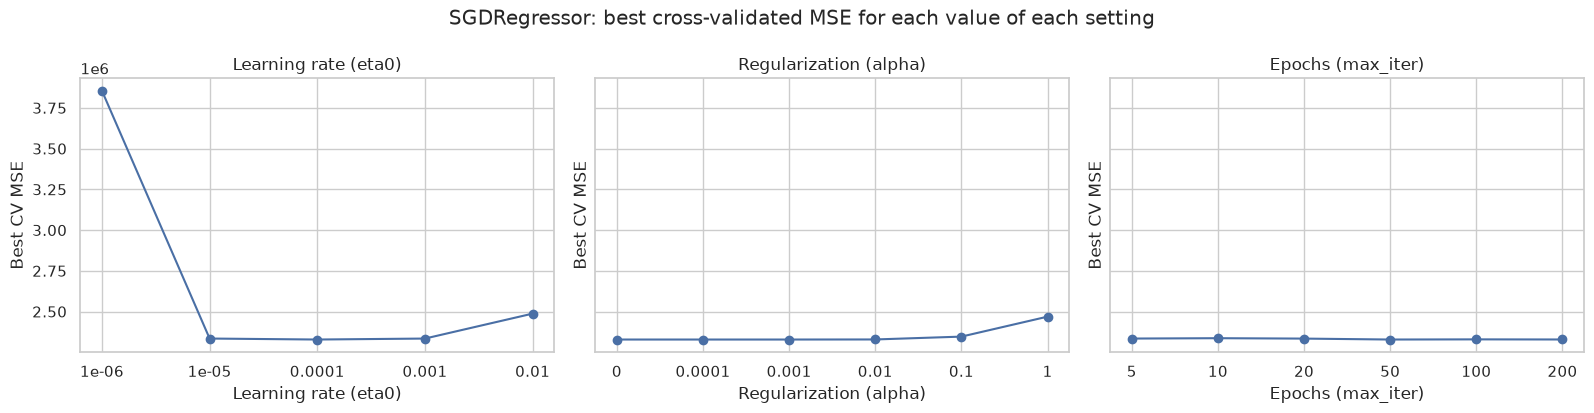

{1e-06: '3,855,004', 1e-05: '2,334,621', 0.0001: '2,328,543', 0.001: '2,334,525', 0.01: '2,487,584'}
{0.0: '2,328,543', 0.0001: '2,328,544', 0.001: '2,328,555', 0.01: '2,328,975', 0.1: '2,346,448', 1.0: '2,468,973'}
{5: '2,334,525', 10: '2,336,726', 20: '2,334,284', 50: '2,328,543', 100: '2,329,528', 200: '2,328,812'}


In [19]:
cv_table = pd.DataFrame(sgd_search.cv_results_)
cv_table["CV MSE"] = -cv_table["mean_test_score"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
labels = {"model__eta0": "Learning rate (eta0)", "model__alpha": "Regularization (alpha)",
          "model__max_iter": "Epochs (max_iter)"}
for ax, (param, label) in zip(axes, labels.items()):
    best_per_value = cv_table.groupby(f"param_{param}")["CV MSE"].min()
    ax.plot(range(len(best_per_value)), best_per_value.values, marker="o", color="#4a6fa5")
    ax.set_xticks(range(len(best_per_value)), [f"{v:g}" for v in best_per_value.index])
    ax.set(title=label, xlabel=label, ylabel="Best CV MSE")
fig.suptitle("SGDRegressor: best cross-validated MSE for each value of each setting")
plt.tight_layout()
plt.show()

for param in labels:
    print(cv_table.groupby(f"param_{param}")["CV MSE"].min().map("{:,.0f}".format).to_dict())

**What it shows.** The learning rate matters most: 0.000001 is too small to get anywhere in the allowed epochs (CV MSE 3.86 million), 0.01 overshoots (2.49 million), and 0.0001 is best (2.33 million). Regularization makes no difference up to 0.01 and hurts from 0.1, and the number of epochs barely matters once the learning rate is right (every value from 5 to 200 lands within 0.4%). **What I decided.** I use a learning rate of 0.0001, no regularization (a model with only 14 weights has little room to overfit) and 50 epochs, the best combination.

In [20]:
evaluate("Linear regression (SGD)", sgd_search.best_estimator_)

Linear regression (SGD): train MSE 2,316,869 | test MSE 2,433,627 | test MAE 1,198 kg/ha


### Loss curve for `SGDRegressor`

scikit-learn does not record the loss per epoch, so this loop trains with `partial_fit`, one epoch at a time, using the tuned learning rate and regularization. Each epoch shuffles the training rows, takes one pass, and then records the train and test MSE. It runs for twice the tuned number of epochs, to show what happens after the tuned stopping point (dashed line).

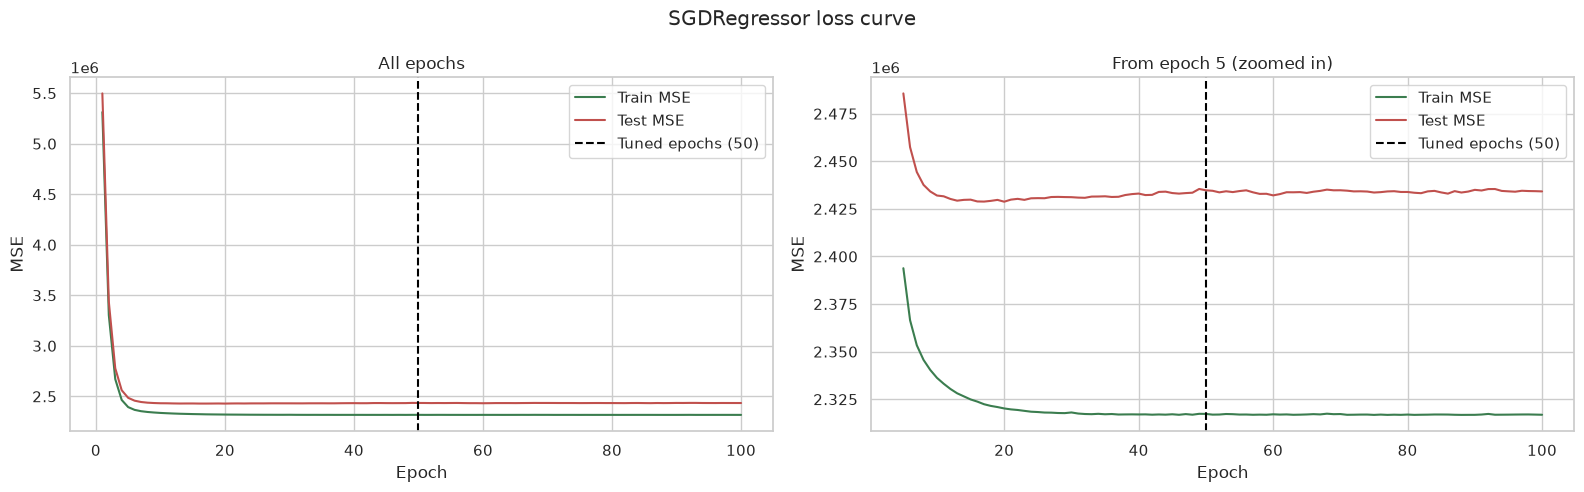

Epoch 1: train 5,312,800 | test 5,497,690
Epoch 50: train 2,317,298 | test 2,434,772
Lowest test MSE: 2,428,777 at epoch 20


In [21]:
curve_prep = build_preprocessor(NUMERIC_FEATURES).fit(X_train)
A_train, A_test = curve_prep.transform(X_train), curve_prep.transform(X_test)
targets_train = y_train.to_numpy()

curve_model = SGDRegressor(learning_rate="constant", eta0=sgd_best["eta0"], alpha=sgd_best["alpha"],
                           random_state=RANDOM_STATE)
rng = np.random.default_rng(RANDOM_STATE)
train_loss, test_loss = [], []
for epoch in range(2 * sgd_best["max_iter"]):
    order = rng.permutation(len(A_train))
    curve_model.partial_fit(A_train[order], targets_train[order])
    train_loss.append(mean_squared_error(y_train, curve_model.predict(A_train)))
    test_loss.append(mean_squared_error(y_test, curve_model.predict(A_test)))

epochs = np.arange(1, len(train_loss) + 1)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, start, title in [(axes[0], 1, "All epochs"), (axes[1], 5, "From epoch 5 (zoomed in)")]:
    shown = epochs >= start
    ax.plot(epochs[shown], np.array(train_loss)[shown], label="Train MSE", color="#3b7d4f")
    ax.plot(epochs[shown], np.array(test_loss)[shown], label="Test MSE", color="#c0504d")
    ax.axvline(sgd_best["max_iter"], color="black", linestyle="--", label=f"Tuned epochs ({sgd_best['max_iter']})")
    ax.set(title=title, xlabel="Epoch", ylabel="MSE")
    ax.legend()
fig.suptitle("SGDRegressor loss curve")
plt.tight_layout()
plt.show()

print(f"Epoch 1: train {train_loss[0]:,.0f} | test {test_loss[0]:,.0f}")
print(f"Epoch {sgd_best['max_iter']}: train {train_loss[sgd_best['max_iter'] - 1]:,.0f} | test {test_loss[sgd_best['max_iter'] - 1]:,.0f}")
print(f"Lowest test MSE: {min(test_loss):,.0f} at epoch {int(np.argmin(test_loss)) + 1}")

**What it shows.** Both losses fall steeply in the first 5 epochs, from about 5.3 million to under 2.6 million, and then flatten. In the zoomed view, the test MSE bottoms out at epoch 20 (2,428,777) and then drifts up by about 0.3% while the train MSE keeps edging down: a very slight sign of overfitting, too small to matter. **What I decided.** I keep the 50 epochs chosen by cross-validation on the training set, because picking epoch 20 from this curve would mean tuning on the test set.

### Decision tree and random forest

Both are tuned with the same 5-fold cross-validation on the training set.

- **Decision tree:** maximum depth, and the minimum number of fields in each leaf.
- **Random forest:** 200 trees. The search tunes the minimum leaf size, the share of features each split may consider, and the maximum depth.

In [22]:
from sklearn.tree import DecisionTreeRegressor

tree_search = GridSearchCV(
    make_model(DecisionTreeRegressor(random_state=RANDOM_STATE)),
    {"model__max_depth": [3, 5, 7, 9, 12, None], "model__min_samples_leaf": [1, 10, 25, 50, 100, 150, 200, 300]},
    cv=kfold, scoring="neg_mean_squared_error", n_jobs=-1,
).fit(X_train, y_train)
print("Decision tree best settings:", tree_search.best_params_)
evaluate("Decision tree", tree_search.best_estimator_)

Decision tree best settings: {'model__max_depth': 9, 'model__min_samples_leaf': 100}
Decision tree: train MSE 2,227,519 | test MSE 2,439,941 | test MAE 1,195 kg/ha


In [23]:
forest_search = GridSearchCV(
    make_model(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
    {"model__min_samples_leaf": [2, 3, 5, 10], "model__max_features": [0.2, 0.33, 0.5, 1.0],
     "model__max_depth": [12, 20, None]},
    cv=kfold, scoring="neg_mean_squared_error", n_jobs=1,
).fit(X_train, y_train)
print("Random forest best settings:", forest_search.best_params_)
evaluate("Random forest", forest_search.best_estimator_)

Random forest best settings: {'model__max_depth': 20, 'model__max_features': 0.33, 'model__min_samples_leaf': 2}


Random forest: train MSE 649,507 | test MSE 2,250,679 | test MAE 1,152 kg/ha


The best single tree needs at least 100 fields per leaf and a depth of 9, because smaller leaves memorise noise. The forest's best settings (leaves of 2 fields, depth 20, a third of the features at each split) fit the training fields far more closely than the test fields (train MSE 649,507 against test MSE 2,250,679). It still has the lowest test error of all four models, because averaging 200 trees cancels much of that noise.

## Comparison of the four models

In [24]:
comparison = pd.DataFrame(results).T.sort_values("Test MSE")
best_name = comparison.index[0]
display(comparison.style.format({"Train MSE": "{:,.0f}", "Test MSE": "{:,.0f}",
                                 "Test RMSE (kg/ha)": "{:,.0f}", "Train MAE (kg/ha)": "{:,.0f}",
                                 "Test MAE (kg/ha)": "{:,.0f}", "Test R²": "{:.3f}"}))
print(f"Best model: {best_name}, with the lowest test MSE ({comparison.loc[best_name, 'Test MSE']:,.0f}).")

,Train MSE,Test MSE,Test RMSE (kg/ha),Train MAE (kg/ha),Test MAE (kg/ha),Test R²
Random forest,"649,507","2,250,679","1,500",611,"1,152",0.244
Linear regression (SGD),"2,316,869","2,433,627","1,560","1,181","1,198",0.183
Linear regression (closed form),"2,316,768","2,433,879","1,560","1,181","1,199",0.183
Decision tree,"2,227,519","2,439,941","1,562","1,156","1,195",0.181


Best model: Random forest, with the lowest test MSE (2,250,679).


**Best model: random forest.** It has the lowest test MSE (2,250,679), about 7.5% below both linear models (2,433,627 and 2,433,879) and the decision tree (2,439,941), and the lowest test MSE is the criterion for choosing the model. It also has the smallest average miss (test MAE 1,152 kg/ha, against 1,195 to 1,199 kg/ha for the other three). The two linear implementations reach the same answer, which confirms that the tuned SGD converged to the closed-form solution. The forest wins because yield does not respond in straight lines: it captures nitrogen levelling off and location changing the effect of other inputs, which the linear models and a single tree cannot.

## Which features matter most to the final model

The importance test earlier used a stand-in forest on all 14 candidates, to decide which features to keep. This one tests the saved random forest itself, on the test set it never trained on. Each input is shuffled 20 times, and the rise in test MSE shows how much the model relies on it. The second table shows the direction: the average predicted yield when an input is set to a typical low value (10th percentile) and a typical high value (90th percentile), with every other input left as observed.

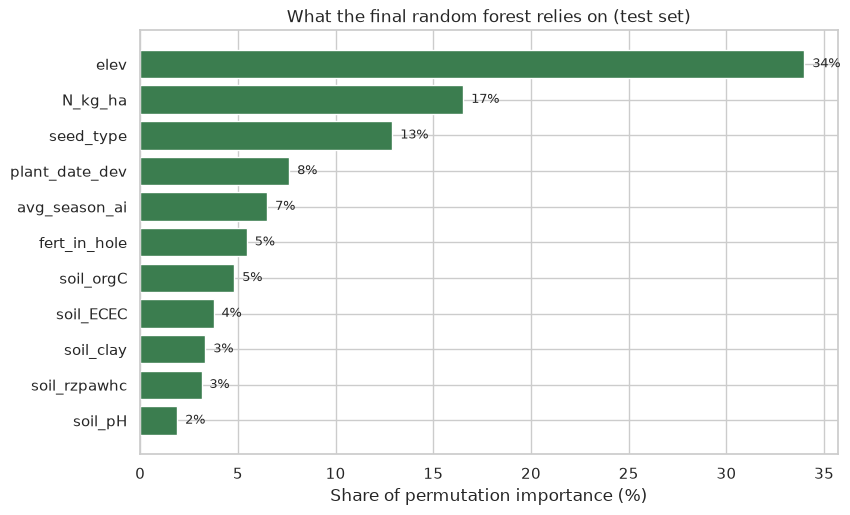

,low value,high value,yield at low,yield at high,change
feature,,,,,
elev,"1,236.0","1,997.5","2,608","3,338",+730
N_kg_ha,0.0,56.9,"2,739","3,328",+589
plant_date_dev,-24.0,27.0,"3,164","2,892",-272
avg_season_ai,1.0,1.4,"3,076","3,049",-27
fert_in_hole,0.0,1.0,"2,971","3,115",+144
soil_orgC,10.0,21.2,"3,018","3,208",+189
soil_ECEC,8.0,15.4,"3,115","3,116",+1
soil_clay,33.0,45.0,"3,099","3,020",-79
soil_rzpawhc,60.0,135.0,"3,117","2,970",-148


,average predicted yield
local_or_opv,2765.0
hybrid_early,3044.0
hybrid_medium,2975.0
hybrid_late,3188.0
hybrid_unknown_maturity,2758.0


In [25]:
final_model = models[best_name]
final_permutation = permutation_importance(final_model, X_test, y_test, scoring="neg_mean_squared_error",
                                           n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
final_importance = pd.Series(final_permutation.importances_mean, index=FEATURES).clip(lower=0)
final_share = (final_importance / final_importance.sum() * 100).sort_values()

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(final_share.index, final_share.values, color="#3b7d4f")
for position, share in enumerate(final_share.values):
    ax.text(share + 0.4, position, f"{share:.0f}%", va="center", fontsize=9)
ax.set(title="What the final random forest relies on (test set)", xlabel="Share of permutation importance (%)")
plt.show()


def average_prediction(feature, value):
    changed = X_train.copy()
    changed[feature] = value
    return final_model.predict(changed).mean()


direction = []
for feature in NUMERIC_FEATURES:
    low, high = (0, 1) if feature == "fert_in_hole" else X_train[feature].quantile([0.1, 0.9])
    low_yield, high_yield = average_prediction(feature, low), average_prediction(feature, high)
    direction.append({"feature": feature, "low value": low, "high value": high, "yield at low": low_yield,
                      "yield at high": high_yield, "change": high_yield - low_yield})
display(pd.DataFrame(direction).set_index("feature").loc[final_share.index[::-1].drop("seed_type")].style.format(
    {"low value": "{:,.1f}", "high value": "{:,.1f}", "yield at low": "{:,.0f}", "yield at high": "{:,.0f}",
     "change": "{:+,.0f}"}))
pd.Series({seed: average_prediction("seed_type", seed) for seed in SEED_TYPES}, name="average predicted yield").round(0).to_frame()

**What it shows.** The final forest leans most on elevation (34% of the importance), nitrogen (17%), seed type (13%) and planting date (8%), which together carry about 71% of what it uses. Higher fields, nitrogen up to about 50 kg/ha, late hybrids rather than local seed, and earlier planting all raise the predicted yield, while aridity and soil ECEC barely move it on their own and only matter in combination with other inputs. **What I decided.** I keep all 11 inputs, because shuffling even the weakest (soil pH, 2%) still raises the test error, and I read these effects as associations in the survey, not proof that changing one input would change a farm's yield.

## Scatter plots: the feature most correlated with yield

The feature is chosen by code, as the one with the largest absolute correlation with yield in the training set.

elev              0.341
N_kg_ha           0.238
soil_orgC         0.228
soil_ECEC         0.146
soil_pH          -0.143
soil_clay         0.114
fert_in_hole      0.102
avg_season_ai     0.072
soil_rzpawhc      0.038
plant_date_dev   -0.028

Most correlated feature: elev (r = 0.341)


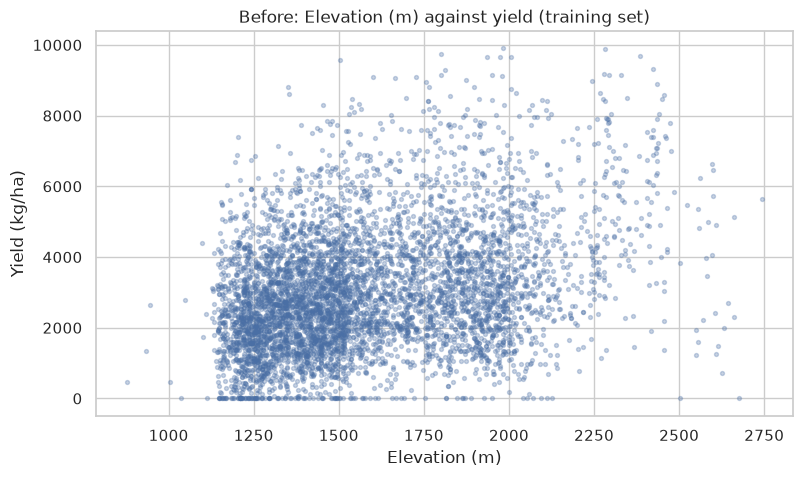

In [26]:
LABELS = {"elev": "Elevation (m)", "N_kg_ha": "Nitrogen (kg/ha)", "soil_orgC": "Soil organic carbon (g/kg)",
          "soil_ECEC": "Soil ECEC (cmol/kg)", "soil_pH": "Soil pH", "soil_clay": "Clay (%)",
          "fert_in_hole": "Fertilizer in hole (1 = yes)", "avg_season_ai": "Aridity index",
          "soil_rzpawhc": "Root-zone water capacity (mm)", "plant_date_dev": "Planting date deviation (days)"}
correlations = X_train[NUMERIC_FEATURES].corrwith(y_train).sort_values(key=abs, ascending=False)
top_feature = correlations.index[0]
print(correlations.round(3).to_string())
print(f"\nMost correlated feature: {top_feature} (r = {correlations.iloc[0]:.3f})")

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(X_train[top_feature], y_train, s=8, alpha=0.3, color="#4a6fa5")
ax.set(title=f"Before: {LABELS[top_feature]} against yield (training set)", xlabel=LABELS[top_feature],
       ylabel="Yield (kg/ha)")
plt.show()

Elevation is the feature most correlated with yield in the training set (r = 0.341). The cloud of points rises with altitude, but at every elevation yields range from zero to nearly 10,000 kg/ha. So next I fit a one-feature line, to see how much elevation explains on its own.

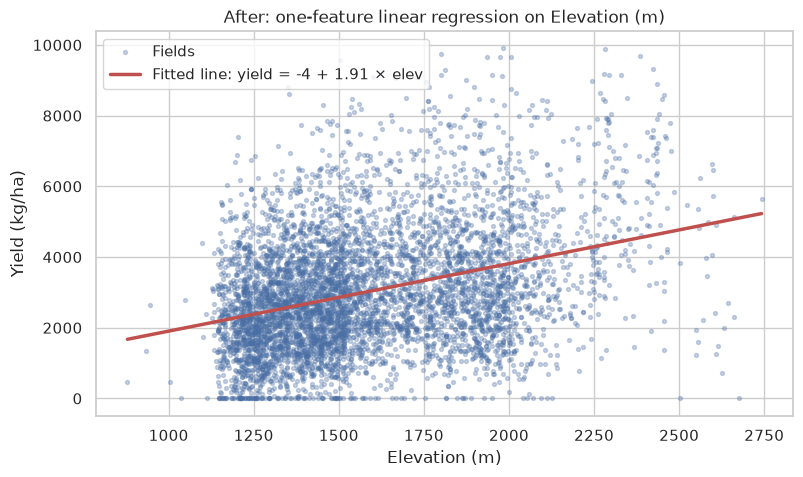

In [27]:
single = X_train[[top_feature]].join(y_train).dropna()
line_model = LinearRegression().fit(single[[top_feature]], single[TARGET])
x_line = pd.DataFrame({top_feature: np.linspace(single[top_feature].min(), single[top_feature].max(), 100)})

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(single[top_feature], single[TARGET], s=8, alpha=0.3, color="#4a6fa5", label="Fields")
ax.plot(x_line[top_feature], line_model.predict(x_line), color="#c0504d", linewidth=2.5,
        label=f"Fitted line: yield = {line_model.intercept_:,.0f} + {line_model.coef_[0]:.2f} × {top_feature}")
ax.set(title=f"After: one-feature linear regression on {LABELS[top_feature]}", xlabel=LABELS[top_feature],
       ylabel="Yield (kg/ha)")
ax.legend()
plt.show()

The fitted line adds about 1.9 kg/ha of yield for every extra metre of elevation, so a field at 2,000 m is expected to yield about 1,900 kg/ha more than one at 1,000 m. Most points sit far from the line, which shows that one feature alone explains little, and why the full models combine 11 features.

## Save the best model and predict one row

The whole pipeline (blank filling, encoding, scaling and the model) is saved with joblib into the API folder, so the API receives the same raw inputs as this notebook.

**Risk bands.** A field is high risk if its predicted yield falls in the bottom third of predictions, and low risk if it falls in the top third. The cut-offs come from out-of-fold predictions on the training set (each field is predicted by a model that did not train on it). Predictions on fields the model has already seen would be overconfident.

**Data for retraining.** The training and test sets are saved next to the model, so the API's retraining step can refit on the original data plus new rows and report the test MSE before and after.

In [28]:
import json
from pathlib import Path

import joblib
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

API_DIR = Path("..") / "API"
API_DIR.mkdir(exist_ok=True)
MODEL_PATH = API_DIR / "best_model.pkl"

best_model = models[best_name]
joblib.dump(best_model, MODEL_PATH, compress=3)

out_of_fold = cross_val_predict(clone(best_model), X_train, y_train, cv=kfold)
high_below, low_from = np.quantile(out_of_fold, [1 / 3, 2 / 3])
risk_bands = {"high_risk_below": round(float(high_below), 1), "low_risk_from": round(float(low_from), 1)}
(API_DIR / "risk_bands.json").write_text(json.dumps(risk_bands, indent=2) + "\n")

X_train.join(y_train).to_csv(API_DIR / "train_data.csv", index=False)
X_test.join(y_test).to_csv(API_DIR / "test_data.csv", index=False)

print(f"Saved {best_name} to {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")
print("Risk band cut-offs (kg/ha):", risk_bands)

Saved Random forest to ../API/best_model.pkl (14.6 MB)
Risk band cut-offs (kg/ha): {'high_risk_below': 2632.1, 'low_risk_from': 3309.9}


In [29]:
def predict_yield(row, model_path=MODEL_PATH):
    model = joblib.load(model_path)
    return float(model.predict(row[FEATURES])[0])


one_row = X_test.iloc[[0]]
display(one_row)
predicted = predict_yield(one_row)
print(f"Predicted yield: {predicted:,.0f} kg/ha | actual yield: {y_test.iloc[0]:,.0f} kg/ha")

,elev,avg_season_ai,soil_rzpawhc,soil_clay,soil_pH,soil_orgC,soil_ECEC,N_kg_ha,plant_date_dev,fert_in_hole,seed_type
6385,1339,0.919853,120.0,32.0,6.2,11.182494,12.463738,22.23945,-16.0,1,hybrid_late


Predicted yield: 2,350 kg/ha | actual yield: 992 kg/ha


## Is the model good enough for insurance?

Three checks on the test set connect the model's error to the insurer's decision.

In [30]:
def risk_band(predicted_yield):
    if predicted_yield < risk_bands["high_risk_below"]:
        return "High risk"
    if predicted_yield < risk_bands["low_risk_from"]:
        return "Medium risk"
    return "Low risk"


test_predictions = best_model.predict(X_test)
bands = pd.DataFrame({"band": [risk_band(p) for p in test_predictions], "actual": y_test.to_numpy()})
bands.groupby("band")["actual"].agg(
    fields="count", median_actual_yield="median", share_under_1000=lambda s: (s < 1000).mean()
).reindex(["High risk", "Medium risk", "Low risk"]).style.format(
    {"median_actual_yield": "{:,.0f}", "share_under_1000": "{:.1%}"})

,fields,median_actual_yield,share_under_1000
band,,,
High risk,483,"2,024",18.2%
Medium risk,478,"2,687",5.6%
Low risk,491,"3,766",2.6%


The bands separate real outcomes on fields the model never saw: high-risk fields have a median actual yield of 2,024 kg/ha and 18.2% of them failed (under 1,000 kg/ha), against 3,766 kg/ha and 2.6% for low-risk fields. A high-risk farm is about seven times as likely to fail as a low-risk one, which is the signal an insurer needs for pricing.

In [31]:
pooled = pd.DataFrame({"zone": kenya.loc[X_test.index, "cz"], "actual": y_test, "predicted": test_predictions})
zones = pooled.groupby("zone").agg(fields=("actual", "size"), mean_actual=("actual", "mean"),
                                   mean_predicted=("predicted", "mean"))
zones = zones[zones["fields"] >= 30]
zones["error %"] = ((zones["mean_predicted"] - zones["mean_actual"]).abs() / zones["mean_actual"] * 100).round(1)

field_error = (pooled["predicted"] - pooled["actual"]).abs().mean() / pooled["actual"].mean() * 100
print(f"Average error for a single field: {field_error:.1f}% of mean yield")
print(f"Average error for a climate zone's mean yield: {zones['error %'].mean():.1f}%")
zones.round(0)

Average error for a single field: 37.8% of mean yield
Average error for a climate zone's mean yield: 5.1%


,fields,mean_actual,mean_predicted,error %
zone,,,,
6501,104,3788.0,4037.0,7.0
6601,49,4370.0,3889.0,11.0
6701,76,3665.0,3734.0,2.0
6801,199,2902.0,3135.0,8.0
7501,73,1846.0,1946.0,5.0
7601,127,2625.0,2640.0,1.0
7701,411,2862.0,2779.0,3.0
7801,323,2959.0,2833.0,4.0


For a single field, the forest is off by about 38% of mean yield on average, which is too much to judge one farm on its own. Averaged over a climate zone, the error falls to about 5% (between 1% and 11% per zone), because over- and under-predictions cancel out. Insurers price pools of farms, not single farms, so this is the level at which the model is useful.

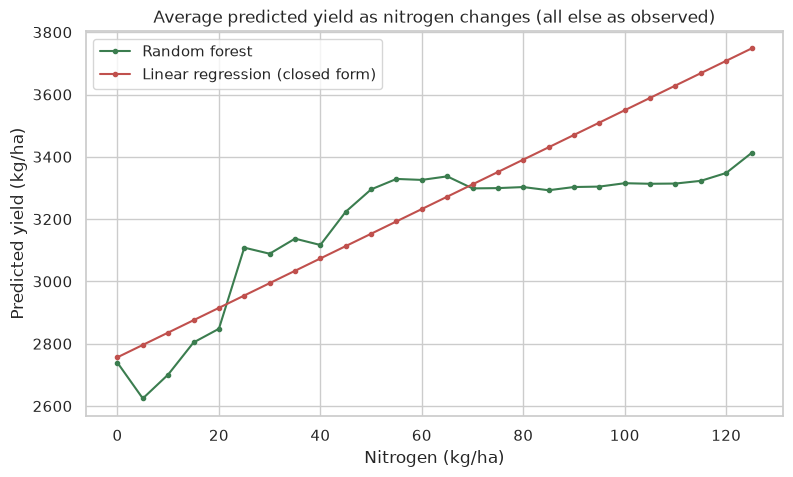

In [32]:
from sklearn.inspection import partial_dependence

grid = pd.DataFrame({"N_kg_ha": np.arange(0, 126, 5)})
fig, ax = plt.subplots(figsize=(9, 5))
for name, color in [(best_name, "#3b7d4f"), ("Linear regression (closed form)", "#c0504d")]:
    dependence = partial_dependence(models[name], X_train, ["N_kg_ha"], custom_values={"N_kg_ha": grid["N_kg_ha"]},
                                    kind="average")
    ax.plot(dependence["grid_values"][0], dependence["average"][0], marker="o", markersize=3, color=color, label=name)
ax.set(title="Average predicted yield as nitrogen changes (all else as observed)",
       xlabel="Nitrogen (kg/ha)", ylabel="Predicted yield (kg/ha)")
ax.legend()
plt.show()

**What it shows.** The linear model can only say that every extra kilogram of nitrogen adds the same amount of yield, forever. The forest learns that predicted yield rises quickly up to about 50 kg/ha and then levels off. **What I concluded.** A straight line cannot capture this levelling off, and it is one reason the forest beats the linear models.

## Conclusion

- **Model:** a random forest using 11 features known at enrolment. Test MSE 2,250,679 (RMSE about 1,500 kg/ha, MAE about 1,150 kg/ha, R² 0.24).
- **Is the loss high?** For a single field, yes: yield also depends on rain, pests and care during the season, which nobody knows at enrolment. For a pool of farms it is low enough to use: zone averages are within about 5%, and the risk bands separate failure rates of 18.2% and 2.6%.
- **How to lower it:** add information that is known at enrolment but missing here, such as seasonal rainfall forecasts, the farm's past yields and repayment records; collect more fields from under-represented areas; and try gradient-boosted trees.
- **Saved for the API:** `../API/best_model.pkl` (the full pipeline), `../API/risk_bands.json`, and the train and test data for retraining.

## Answers to the four questions

**1. Is my test loss high or low for this use case, and what would I do to reduce it further?**
My best model, the random forest, has a test MSE of 2,250,679. That's an RMSE of about 1,500 kg/ha and an average miss (MAE) of about 1,150 kg/ha, against a mean yield of about 3,050 kg/ha. For a single field that's high, about 38% off, because a lot of what decides yield happens after the farmer signs up: rain, pests and weeding. The model can't see any of that on enrolment day. For insurance it's good enough. Averaged over a climate zone the error drops to about 5%, and insurers price groups of farms, not single farms. To reduce it further I'd add each farm's past yields, satellite history of the plot and seasonal rainfall forecasts, collect more seasons of data, and try gradient boosting.

**2. Which hyperparameters did I tune, and how did each change the loss?**
All tuning used 5-fold cross-validation on the training set only.
- **SGD learning rate (`eta0`)** mattered most. Too small (0.000001) learns too slowly (CV MSE 3.86 million), too big (0.01) overshoots (2.49 million), and 0.0001 is best (2.33 million).
- **SGD regularization (`alpha`)** didn't help, so I set it to 0.
- **SGD epochs (`max_iter`):** anything from 5 to 200 lands within 0.4%, so I kept 50. The loss curve shows test loss lowest at epoch 20, but picking from the test curve would be tuning on the test set.
- **Decision tree:** small leaves memorise the noise in field data. Best was depth 9 with at least 100 fields per leaf.
- **Random forest:** best was leaves of 2, a third of the features per split and depth 20, with 200 trees. Deep trees are fine here because averaging cancels their noise.

**3. What happens when new data arrives, and how is my deployed model updated?**
New data comes in as a CSV uploaded to `/retrain`, and the upload itself starts the retrain. Every row is checked (columns, blanks, types and ranges), and one bad row rejects the whole file with its line number. Rows already in the training data are skipped. The random forest is refitted with the same settings on the old plus new rows, tested on the same test set, and the risk bands are updated. `/predict` uses the new model straight away, with no restart. The retrained model lives in memory, so when Render restarts it goes back to `best_model.pkl`.

**4. Why did I configure the CORS middleware the way I did?**
CORS is a browser rule, so my Flutter app on the phone isn't affected by it. I only allow my Render site and `localhost:8080` (for running Flutter on the web while developing), only GET and POST, and only the Content-Type and Accept headers. Every other website is blocked, and credentials are off because the API has no login. I allow only what the app needs and nothing more.